PANDAS

In [17]:
import pandas as pd
import os 
import numpy as np 
from tqdm import tqdm
import seaborn as sns
import matplotlib.pyplot as plt

def count_df (data_path, embedding_path, NAME,slide_col='image_id', printing=False):
    features_list = []
    labels_list = []
    patient_list = []
    gleason_score = []
    gleason_primary_list = []
    gleason_secondary_list = []
    df = pd.read_excel(data_path)
    embeddings = [f for f in os.listdir(embedding_path) if f.endswith('.npy')]

    # Agrega tqdm aquí
    for f in tqdm(embeddings, desc="Procesando embeddings"):
        slide_id = f.split('.npy')[0]
        if NAME == 'SICAP':
            slide_id = slide_id.split('_')[0]
        row = df[df[slide_col] == slide_id]

        if not row.empty:
            ruta_npy = os.path.join(embedding_path, f)

            gleason = row[['gleason_score']].values
            patient_select = row['image_id'].values
            labels_selected = row[['gleason_primary', 'gleason_secondary']].values
            labels_selected = np.array(labels_selected, dtype=int)[0]

            gleason_score.append(gleason.item())
            features_list.append(ruta_npy)
            labels_list.append(labels_selected)
            patient_list.append(patient_select)
            gleason_primary_list.append(row['gleason_primary'].values[0])
            gleason_secondary_list.append(row['gleason_secondary'].values[0])
    
   
    
    # Crear DataFrame con los valores
    df_gleason = pd.DataFrame({
        'Gleason_primary': gleason_primary_list,
        'Gleason_secondary': gleason_secondary_list
    })

    # Crear la tabla cruzada (conteo de combinaciones)
    tabla = pd.crosstab(df_gleason['Gleason_primary'], df_gleason['Gleason_secondary'])
  
    if printing == True:
        print(f"Nº imagenes en Base de datos {NAME} : {len(features_list)}")
        print(f"Nº de pacientes en {NAME}: {len(patient_list)}")

        plt.figure(figsize=(6,5))
        sns.heatmap(tabla, annot=True, fmt='d', cmap='Blues')
        plt.xlabel('Gleason secundario')
        plt.ylabel('Gleason primario')
        plt.title('Distribución Gleason Primario vs Secundario')
        plt.show()

    df_train = pd.DataFrame({
        'features': features_list,
        'labels': labels_list,
        'gleason_score': gleason_score,
        'gleason_primary': gleason_primary_list,
        'gleason_secondary': gleason_secondary_list
    })

    return df_train



Procesando embeddings: 100%|██████████| 10569/10569 [00:14<00:00, 719.70it/s]


Nº imagenes en Base de datos PANDA : 9614
Nº de pacientes en PANDA: 9614


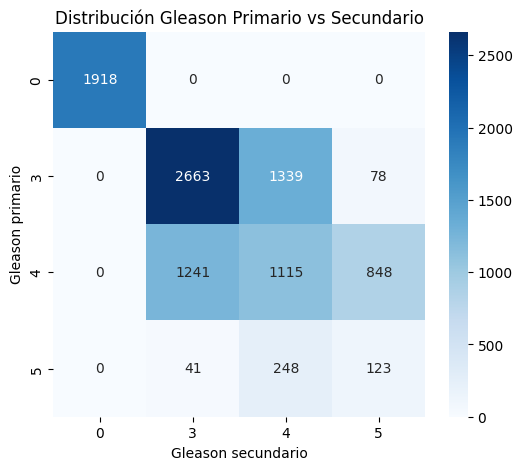

In [18]:
data_path_panda = '/workspace/data/datos_PANDAS.xlsx'
embedding_path_panda = '/workspace/data/pandas/embeddings/KEEP'
df_pandas = count_df (data_path_panda, embedding_path_panda, 'PANDA',slide_col='image_id', printing=True)

Procesando embeddings:   0%|          | 0/167 [00:00<?, ?it/s]

Procesando embeddings: 100%|██████████| 167/167 [00:00<00:00, 1049.67it/s]


Nº imagenes en Base de datos SICAP : 161
Nº de pacientes en SICAP: 161


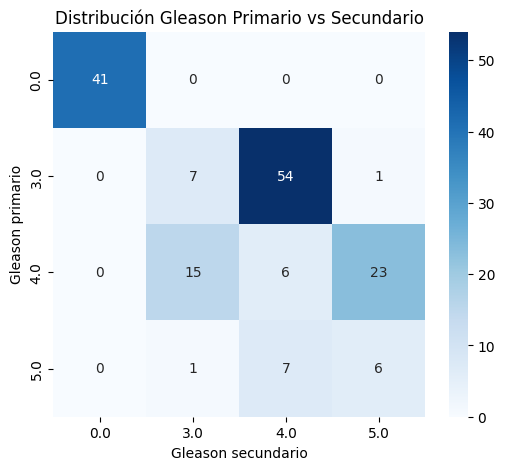

In [19]:
data_path = '/workspace/data/wsi_labels_changed_SICAP.xlsx'
embedding_path = '/workspace/data/features_SICAP/embeddings/KEEP'
df_sicap = count_df (data_path, embedding_path, 'SICAP',slide_col='image_id', printing=True)

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

from sklearn.model_selection import train_test_split
import pandas as pd

def generar_tabla_resumen(df_pandas):
    # --- 1️⃣ Dividir en train, val y test ---
    train_val_idx, test_idx = train_test_split(
        df_pandas.index, test_size=0.15, stratify=df_pandas["gleason_score"]
    )

    train_idx, val_idx = train_test_split(
        train_val_idx, test_size=0.10, stratify=df_pandas.loc[train_val_idx]["gleason_score"]
    )

    # Crear subconjuntos
    df_train = df_pandas.loc[train_idx]
    df_val = df_pandas.loc[val_idx]
    df_test = df_pandas.loc[test_idx]

    # --- 2️⃣ Función auxiliar para contar clases ---
    def contar_por_columna(df, columna):
        return df[columna].value_counts().sort_index()

    # --- 3️⃣ Construir tablas ---
    tipos = ['gleason_primary', 'gleason_secondary', 'gleason_score']
    tablas = {}

    for tipo in tipos:
        # Combinar en un solo DataFrame
        tabla = pd.concat([
            contar_por_columna(df_train, tipo).rename('Train'),
            contar_por_columna(df_val, tipo).rename('Validation'),
            contar_por_columna(df_test, tipo).rename('Test')
        ], axis=1).fillna(0).astype(int)

        tablas[tipo] = tabla

    # --- 4️⃣ Mostrar resultados ---
    for nombre, tabla in tablas.items():
        print(f"\n📊 Tabla resumen por {nombre.replace('_', ' ').title()}")
        print(tabla)
    
    return tablas  # Devuelve un diccionario con las 3 tablas


In [ ]:
tabla = generar_tabla_resumen(df_pandas)


📊 Tabla resumen por Gleason Primary
   Train  Validation  Test
0   1467         163   288
3   3129         348   603
4   2446         275   483
5    311          32    69

📊 Tabla resumen por Gleason Secondary
   Train  Validation  Test
0   1467         163   288
3   3010         335   600
4   2065         230   407
5    811          90   148

📊 Tabla resumen por Gleason Score
    Train  Validation  Test
0    1467         163   288
6    2036         227   400
7    1973         220   387
8     944         105   185
9     838          93   165
10     95          10    18
